In [1]:
import os
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "US_Accidents_March23.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "sobhanmoosavi/us-accidents",
  file_path,
  pandas_kwargs={"dtype": {
      **{c: "category" for c in ["Source", "State", "Country", "Timezone",
          "Airport_Code", "Weather_Condition", "Wind_Direction", "Sunrise_Sunset",
          "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]},
      **{c: "float32" for c in ["End_Lat", "End_Lng", "Distance(mi)",
          "Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
          "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]},
      "Severity": "int8",
  }},
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("5 pierwszych rekordów:", df.head())

c:\Users\kubaz\Desktop\ZSSI\Projekt\ZSSI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\523636962.py:11: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


5 pierwszych rekordów:     ID   Source  Severity           Start_Time             End_Time  \
0  A-1  Source2         3  2016-02-08 05:46:00  2016-02-08 11:00:00   
1  A-2  Source2         2  2016-02-08 06:07:59  2016-02-08 06:37:59   
2  A-3  Source2         2  2016-02-08 06:49:27  2016-02-08 07:19:27   
3  A-4  Source2         3  2016-02-08 07:23:34  2016-02-08 07:53:34   
4  A-5  Source2         2  2016-02-08 07:39:07  2016-02-08 08:09:07   

   Start_Lat  Start_Lng  End_Lat  End_Lng  Distance(mi)  ... Roundabout  \
0  39.865147 -84.058723      NaN      NaN          0.01  ...      False   
1  39.928059 -82.831184      NaN      NaN          0.01  ...      False   
2  39.063148 -84.032608      NaN      NaN          0.01  ...      False   
3  39.747753 -84.205582      NaN      NaN          0.01  ...      False   
4  39.627781 -84.188354      NaN      NaN          0.01  ...      False   

  Station   Stop Traffic_Calming Traffic_Signal Turning_Loop Sunrise_Sunset  \
0   False  False    

# Analiza wypadkow drogowych w USA

# Import wymaganych bibliotek

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as mn
import plotly.graph_objects as go

# Przygotowanie danych

### Informacje

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7728394 entries, 0 to 7728393
Data columns (total 46 columns):
 #   Column                 Dtype   
---  ------                 -----   
 0   ID                     str     
 1   Source                 category
 2   Severity               int8    
 3   Start_Time             str     
 4   End_Time               str     
 5   Start_Lat              float64 
 6   Start_Lng              float64 
 7   End_Lat                float32 
 8   End_Lng                float32 
 9   Distance(mi)           float32 
 10  Description            str     
 11  Street                 str     
 12  City                   str     
 13  County                 str     
 14  State                  category
 15  Zipcode                str     
 16  Country                category
 17  Timezone               category
 18  Airport_Code           category
 19  Weather_Timestamp      str     
 20  Temperature(F)         float32 
 21  Wind_Chill(F)          float32 
 22  Humid

#### Kolumny ramki danych

In [4]:
df.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='str')

#### Statystyki opisowe każdej kolumny numerycznej

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Severity,7728394.0,2.212384,0.487531,1.000000,2.000000,2.000000,2.000000,4.000000
Start_Lat,7728394.0,36.201195,5.076079,24.554800,33.399631,35.823974,40.084959,49.002201
Start_Lng,7728394.0,-94.702545,17.391756,-124.623833,-117.219396,-87.766616,-80.353676,-67.113167
End_Lat,4325632.0,36.261829,5.272904,24.566013,33.462070,36.183495,40.178921,49.075001
End_Lng,4325632.0,-95.725563,18.107927,-124.545746,-117.754341,-88.027893,-80.247086,-67.109245
Distance(mi),7728394.0,0.561842,1.776811,0.000000,0.000000,0.030000,0.464000,441.750000
Temperature(F),7564541.0,61.663288,19.013653,-89.000000,49.000000,64.000000,76.000000,207.000000
Wind_Chill(F),5729375.0,58.251045,22.389832,-89.000000,43.000000,62.000000,75.000000,207.000000
Humidity(%),7554250.0,64.831039,22.820969,1.000000,48.000000,67.000000,84.000000,100.000000
Pressure(in),7587715.0,29.538986,1.006190,0.000000,29.370001,29.860001,30.030001,58.630001


#### Kolumny numeryczne do analizy

In [6]:
# Dane typu int, float i boolean
print(df.count(numeric_only=True))
print("łaczna liczba kolumn numerycznych:", len(df.count(numeric_only=True)))

Severity             7728394
Start_Lat            7728394
Start_Lng            7728394
End_Lat              4325632
End_Lng              4325632
Distance(mi)         7728394
Temperature(F)       7564541
Wind_Chill(F)        5729375
Humidity(%)          7554250
Pressure(in)         7587715
Visibility(mi)       7551296
Wind_Speed(mph)      7157161
Precipitation(in)    5524808
Amenity              7728394
Bump                 7728394
Crossing             7728394
Give_Way             7728394
Junction             7728394
No_Exit              7728394
Railway              7728394
Roundabout           7728394
Station              7728394
Stop                 7728394
Traffic_Calming      7728394
Traffic_Signal       7728394
Turning_Loop         7728394
dtype: int64
łaczna liczba kolumn numerycznych: 26


### Procent brakujacych wartości

In [7]:
missing_values = df.isna().sum().sort_values(ascending=False)
missing_percentage = missing_values[missing_values!=0]/len(df)*100
print(" Procent brakujacych warto?ci \n", missing_percentage)

 Procent brakujacych warto?ci 
 End_Lng                  44.029355
End_Lat                  44.029355
Precipitation(in)        28.512858
Wind_Chill(F)            25.865904
Wind_Speed(mph)           7.391355
Visibility(mi)            2.291524
Wind_Direction            2.267043
Humidity(%)               2.253301
Weather_Condition         2.244438
Temperature(F)            2.120143
Pressure(in)              1.820288
Weather_Timestamp         1.555666
Sunrise_Sunset            0.300787
Civil_Twilight            0.300787
Astronomical_Twilight     0.300787
Nautical_Twilight         0.300787
Airport_Code              0.292881
Street                    0.140637
Timezone                  0.101030
Zipcode                   0.024779
City                      0.003274
Description               0.000065
dtype: float64


Uzyskanie listy kolumn zawierajacych wartości puste

In [8]:
null_cols = [i for i in df.columns if df[i].isnull().any()]
print(null_cols)

['End_Lat', 'End_Lng', 'Description', 'Street', 'City', 'Zipcode', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']


Sprawdzenie wzorca brakujacych wartości w ramce danych

<Axes: >

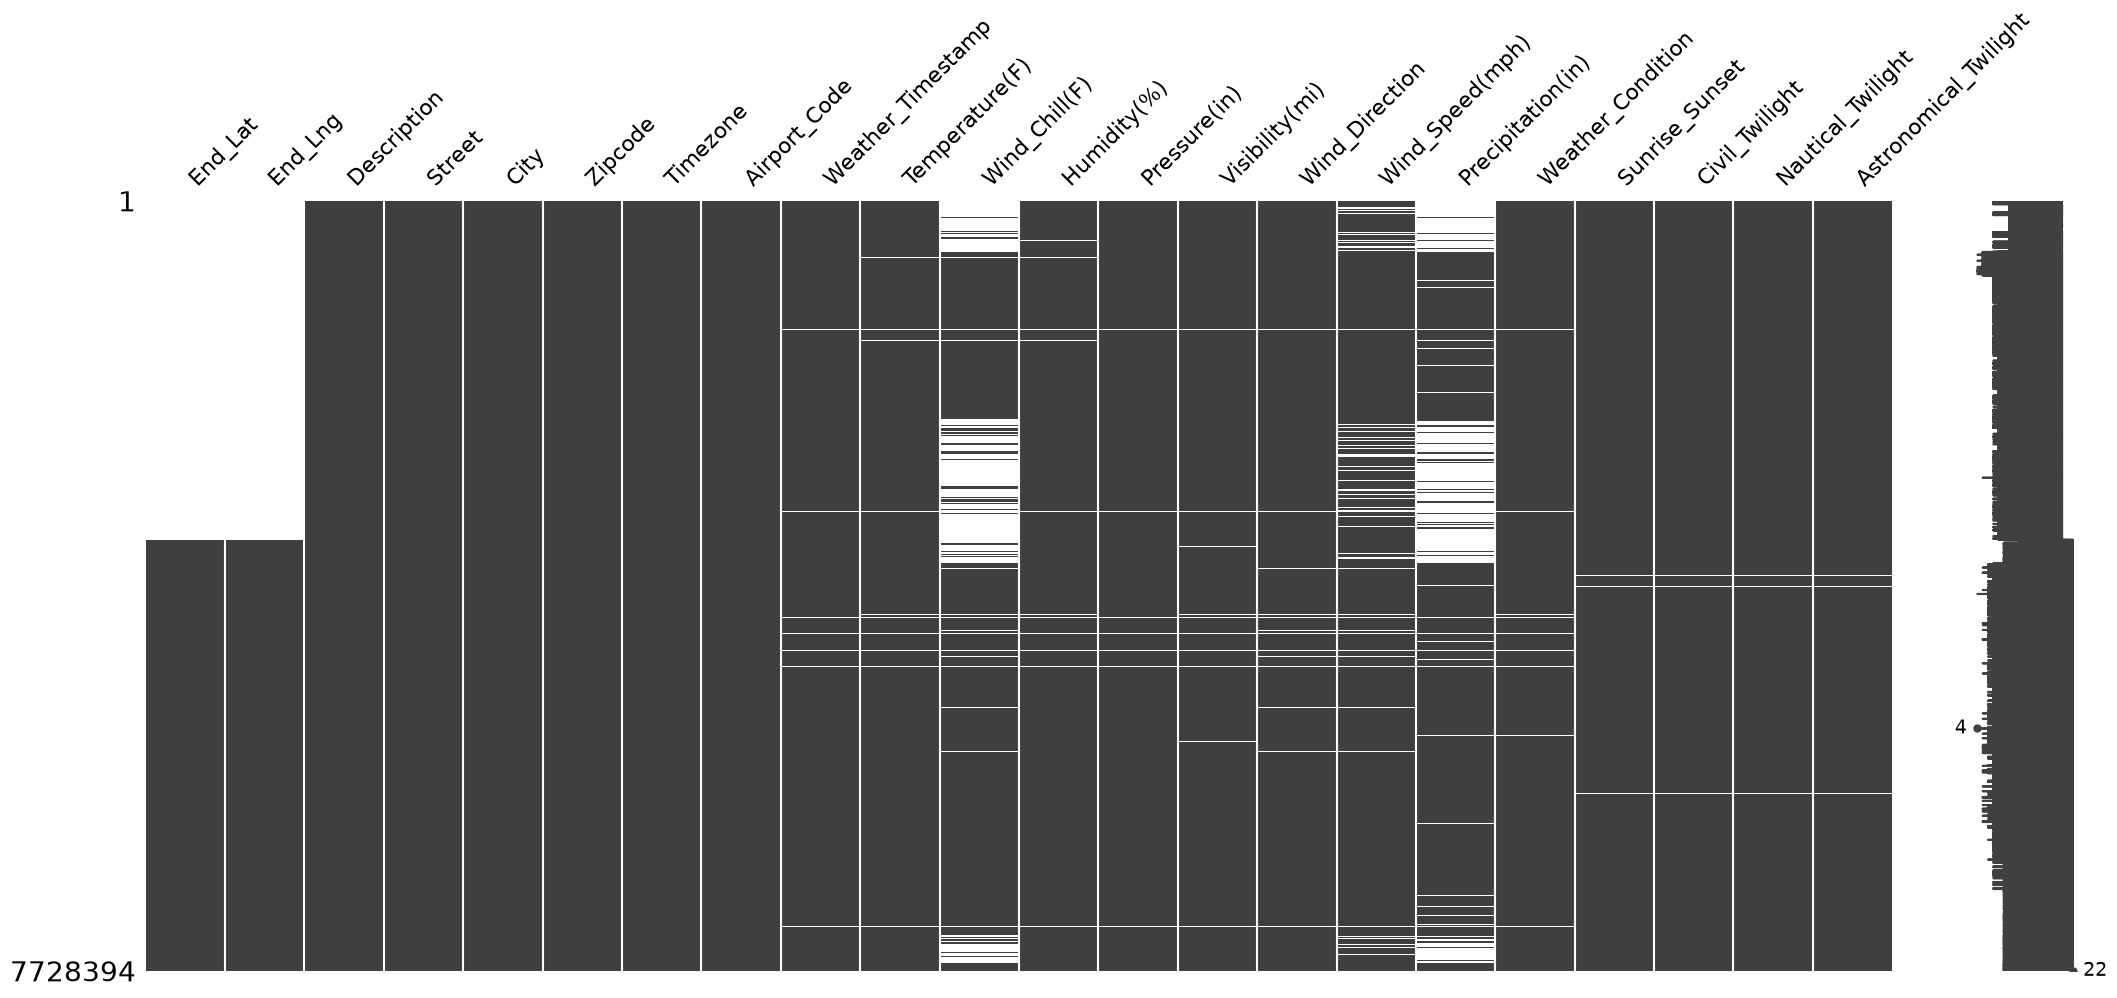

In [9]:
mn.matrix(df[null_cols])

Usuniecie kolumn [End_Lng, End_Lat] zawierajacych duzo brakujacych wartosci, i wierszy też gdzie se nulle

In [10]:
new_data_a = df.drop(columns=["End_Lng", "End_Lat"], axis=0)
new_data_b = new_data_a.dropna(subset = ['Visibility(mi)','Weather_Condition','Humidity(%)',
                                         'Temperature(F)','Wind_Direction','Pressure(in)',
                                         'Weather_Timestamp','Airport_Code','Timezone',
                                         'Zipcode','Sunrise_Sunset','Civil_Twilight',
                                         'Nautical_Twilight','Astronomical_Twilight',
                                         'City','Description'])

dataf = new_data_b.drop(columns = 'ID', axis=0)

### Usuwemy wiersze z brakujecymi wartosciami w kolumnach o najmniejszym odsetku brakow 
### dodetkowo breki w reszcie uzupełniemy średnie ( to tylko tymczesowo)

In [11]:
dataf["Wind_Chill(F)"] = dataf['Wind_Chill(F)'].fillna(dataf['Wind_Chill(F)'].mean())
dataf["Precipitation(in)"] = dataf['Precipitation(in)'].fillna(dataf['Precipitation(in)'].mean())
dataf["Wind_Speed(mph)"] = dataf['Wind_Speed(mph)'].fillna(dataf['Wind_Speed(mph)'].mean())

In [12]:
final_data = dataf.reindex(copy=True)
final_data.head()

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\1636506883.py:1: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  final_data = dataf.reindex(copy=True)


,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Description,Street,City,...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,0.01,Right lane blocked due to accident on I-70 Eas...,I-70 E,Dayton,...,False,False,False,False,False,False,Night,Night,Night,Night
1,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,0.01,Accident on Brice Rd at Tussing Rd. Expect del...,Brice Rd,Reynoldsburg,...,False,False,False,False,False,False,Night,Night,Night,Day
2,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,0.01,Accident on OH-32 State Route 32 Westbound at ...,State Route 32,Williamsburg,...,False,False,False,False,True,False,Night,Night,Day,Day
3,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,0.01,Accident on I-75 Southbound at Exits 52 52B US...,I-75 S,Dayton,...,False,False,False,False,False,False,Night,Day,Day,Day
4,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,0.01,Accident on McEwen Rd at OH-725 Miamisburg Cen...,Miamisburg Centerville Rd,Dayton,...,False,False,False,False,True,False,Day,Day,Day,Day


# Analiza wypadkow wedlug lokalizacji

In [13]:
print("Kody stanow: ", final_data.State.unique())
print("Łaczna liczba stanow w zbiorze danych: ", len(final_data.State.unique()))

Kody stanow:  ['OH', 'WV', 'CA', 'FL', 'GA', ..., 'WY', 'ID', 'ND', 'MT', 'SD']
Length: 49
Categories (49, str): ['AL', 'AR', 'AZ', 'CA', ..., 'WA', 'WI', 'WV', 'WY']
Łaczna liczba stanow w zbiorze danych:  49


C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\1608040503.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="State", data=final_data, orient = 'v', palette = "crest_r", order = final_data['State'].value_counts().index)


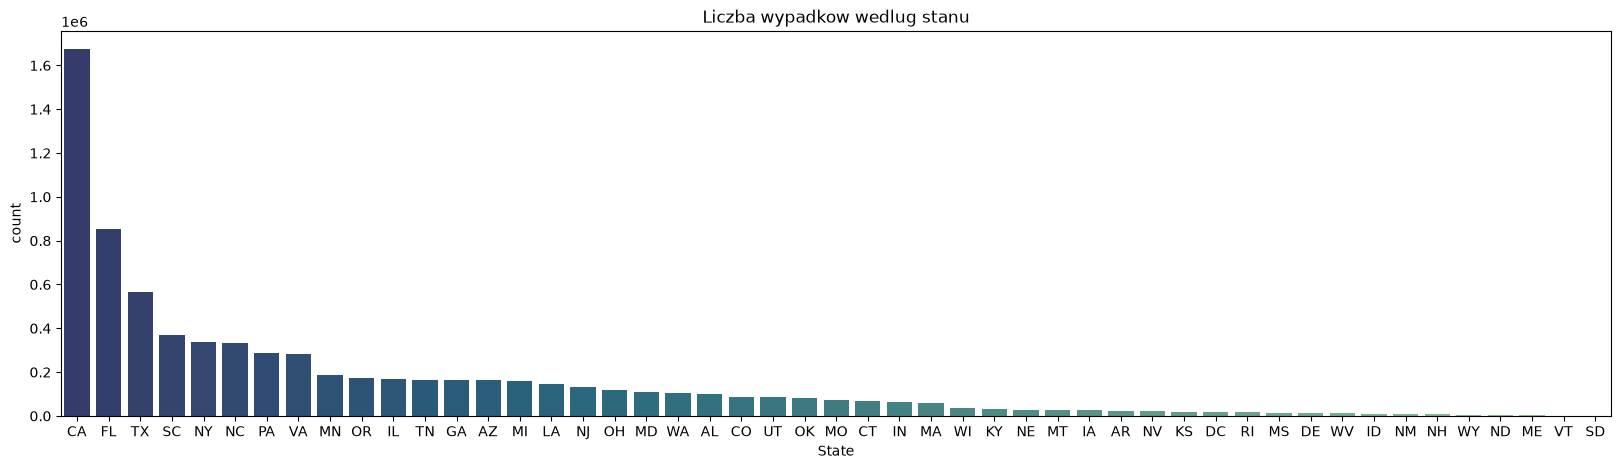

In [14]:
fig, ax = plt.subplots(figsize = (20,5))
c = sns.countplot(x="State", data=final_data, orient = 'v', palette = "crest_r", order = final_data['State'].value_counts().index)
c.set_title("Liczba wypadkow wedlug stanu");

In [15]:
print("Nazwy miast: ", final_data.City.unique())
print("Łaczna liczba miast w zbiorze danych: ", len(final_data.City.unique()))

Nazwy miast:  <StringArray>
[                      'Dayton',                 'Reynoldsburg',
                 'Williamsburg',                  'Westerville',
                     'Columbus',                   'Miamisburg',
                    'Johnstown',                       'Dublin',
             'Canal Winchester',                      'Lebanon',
 ...
                      'Leadore',                   'Vallecitos',
                    'Guildhall',              'Sandy River Plt',
                       'Lublin',                     'Fairbank',
                    'Pond Eddy',                    'Ness City',
                   'Clarksdale', 'American Fork-Pleasant Grove']
Length: 12237, dtype: str
Łaczna liczba miast w zbiorze danych:  12237


C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2651272541.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="City", data=final_data, order=final_data.City.value_counts().iloc[:50].index, orient = 'v', palette = "crest_r")
C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2651272541.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  c.set_xticklabels(c.get_xticklabels(), rotation=90)


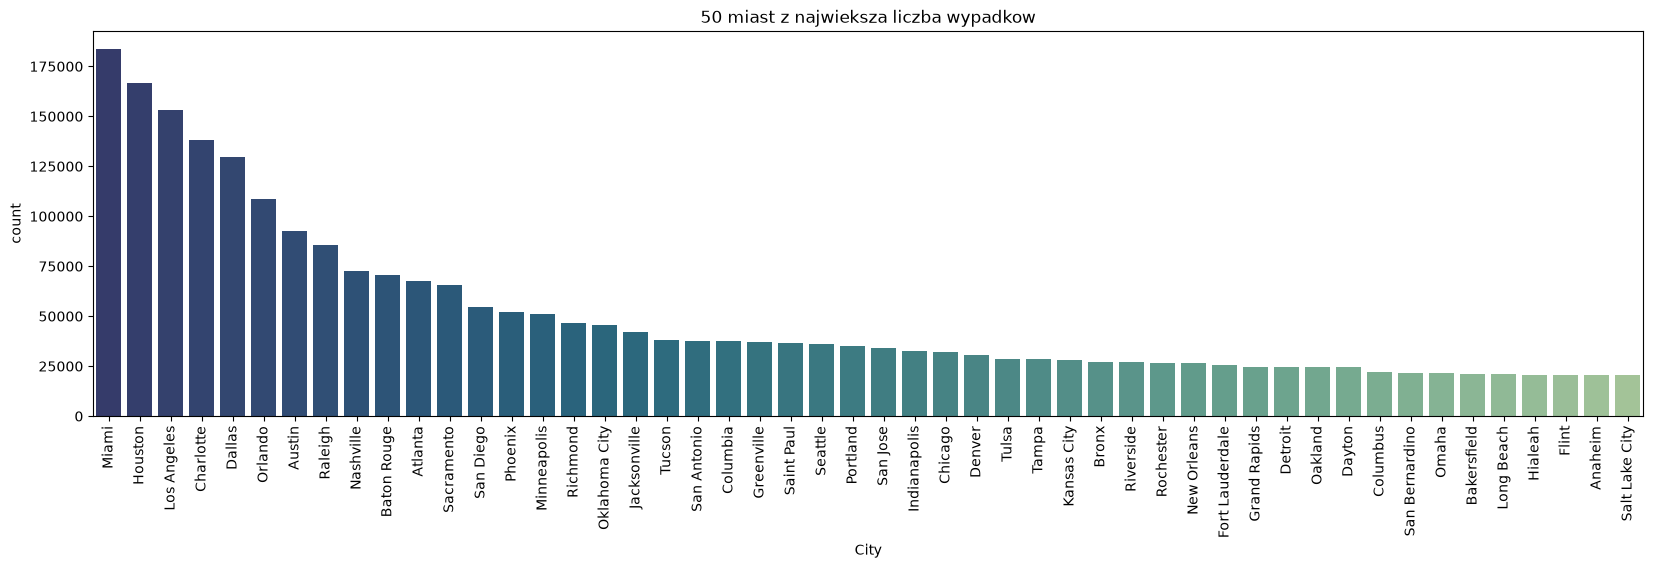

In [16]:
fig, ax = plt.subplots(figsize = (20,5))
c = sns.countplot(x="City", data=final_data, order=final_data.City.value_counts().iloc[:50].index, orient = 'v', palette = "crest_r")
c.set_title("50 miast z najwieksza liczba wypadkow")
c.set_xticklabels(c.get_xticklabels(), rotation=90)
plt.show()

# Przygotowanie znacznikow czasu

In [17]:
final_data.Start_Time = pd.to_datetime(final_data.Start_Time, format='mixed')
final_data.Start_Time[0]

Timestamp('2016-02-08 05:46:00')

## zbiory ne bezie czesu

In [18]:
final_data['Month'] = final_data['Start_Time'].dt.month
final_data['Year'] = final_data['Start_Time'].dt.year
final_data['Hour'] = final_data['Start_Time'].dt.hour
final_data['Weekday'] = final_data['Start_Time'].dt.weekday
#yearly data subset 
data_2016 = final_data[final_data.Start_Time.dt.year == 2016]
data_2017 = final_data[final_data.Start_Time.dt.year == 2017]
data_2018 = final_data[final_data.Start_Time.dt.year == 2018]
data_2019 = final_data[final_data.Start_Time.dt.year == 2019]
data_2020 = final_data[final_data.Start_Time.dt.year == 2020]
data_2021 = final_data[final_data.Start_Time.dt.year == 2021]
data_2022 = final_data[final_data.Start_Time.dt.year == 2022]
data_2023 = final_data[final_data.Start_Time.dt.year == 2023]
data_2017_2019 = final_data[(final_data["Year"] >= 2017) & (final_data["Year"] <= 2019)]

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\3021812019.py:4: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  final_data['Weekday'] = final_data['Start_Time'].dt.weekday


# Roczna analiza wypadkow

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\1079072220.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Year", data=final_data, orient = 'v', palette = "crest")


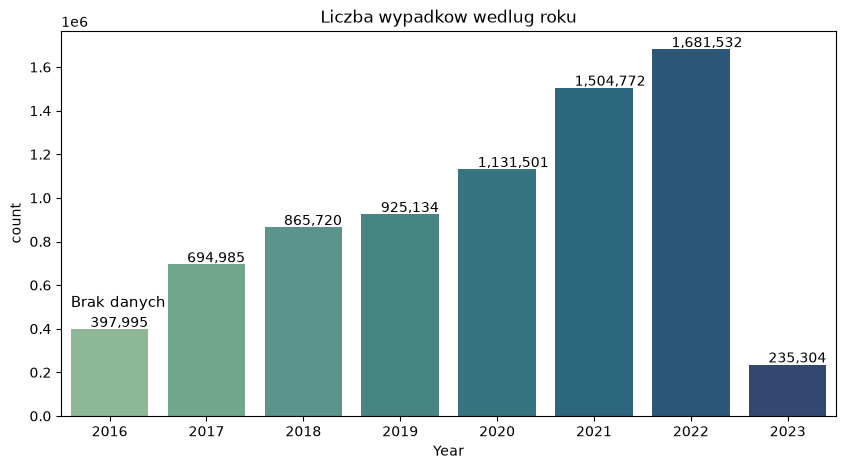

In [19]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Year", data=final_data, orient = 'v', palette = "crest")
plt.annotate('Brak danych',xy=(-0.4,500000), fontsize=11)
c.set_title("Liczba wypadkow wedlug roku")
for i in ax.patches:
    count = '{:,.0f}'.format(i.get_height())
    x = i.get_x()+i.get_width()-0.60
    y = i.get_height()+10000
    ax.annotate(count, (x, y))
plt.show()

# Miesieczna analiza wypadkow

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2073405527.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Month", data=data_2016, orient = 'v', palette = "crest")


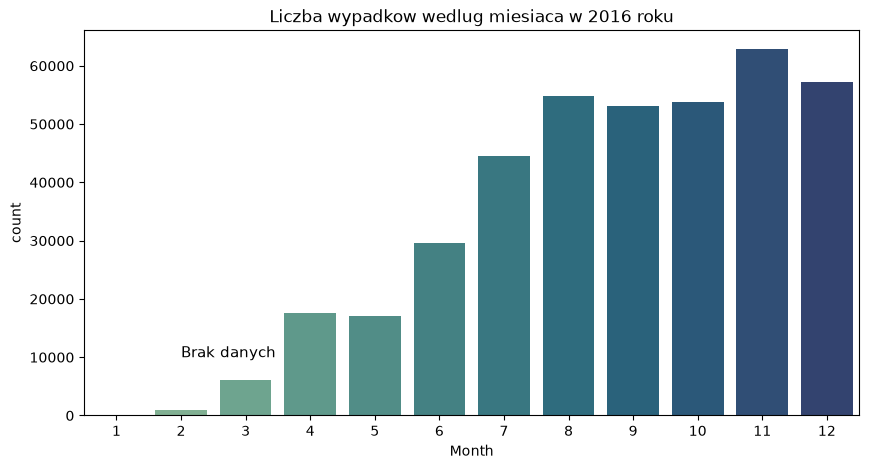

In [20]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Month", data=data_2016, orient = 'v', palette = "crest")
plt.annotate('Brak danych',xy=(1,10000), fontsize=11)
c.set_title("Liczba wypadkow wedlug miesiaca w 2016 roku")
plt.show()

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\1888632759.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Month", data=data_2017_2019, orient = 'v', palette = "crest")


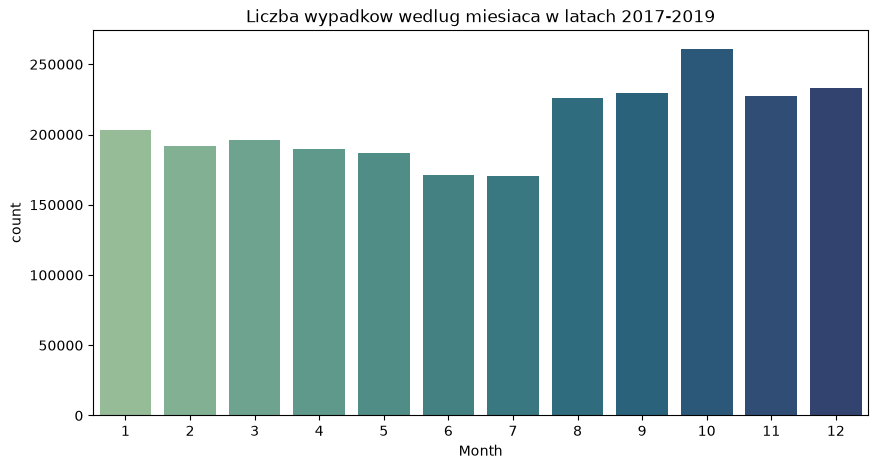

In [21]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Month", data=data_2017_2019, orient = 'v', palette = "crest")
c.set_title("Liczba wypadkow wedlug miesiaca w latach 2017-2019")
plt.show()

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\418945544.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Month", data=data_2020, orient = 'v', palette = "crest")


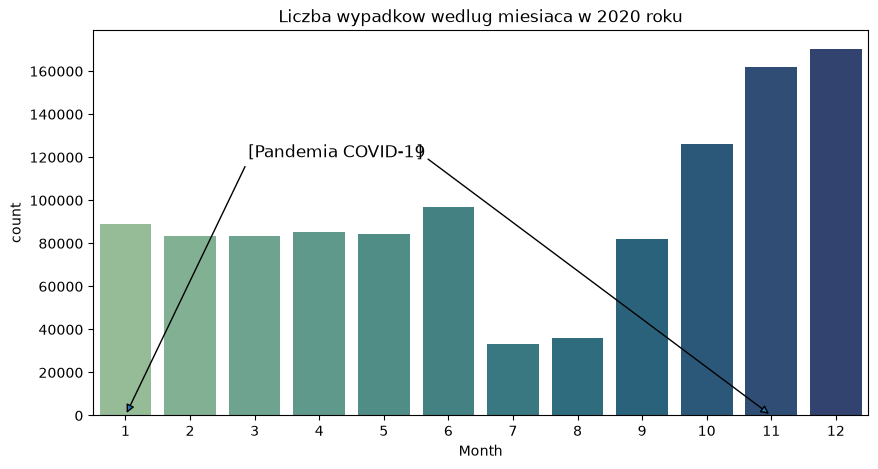

In [22]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Month", data=data_2020, orient = 'v', palette = "crest")
plt.annotate('Pandemia COVID-19',xy=(2,120000), fontsize=12)
plt.annotate("[",xy=(0,0),xytext=(1.9,120000),arrowprops={'arrowstyle':'-|>'}, fontsize=12)
plt.annotate("]",xy=(10,0),xytext=(4.5,120000),arrowprops={'arrowstyle':'-|>'}, fontsize=12)
c.set_title("Liczba wypadkow wedlug miesiaca w 2020 roku")
plt.show()

# Tygodniowa analiza wypadkow

## Wszystkie tygodnie 2022 roku

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\156025945.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x=data_2022.Start_Time.dt.isocalendar().week, data=data_2022, orient = 'v', palette = "crest")


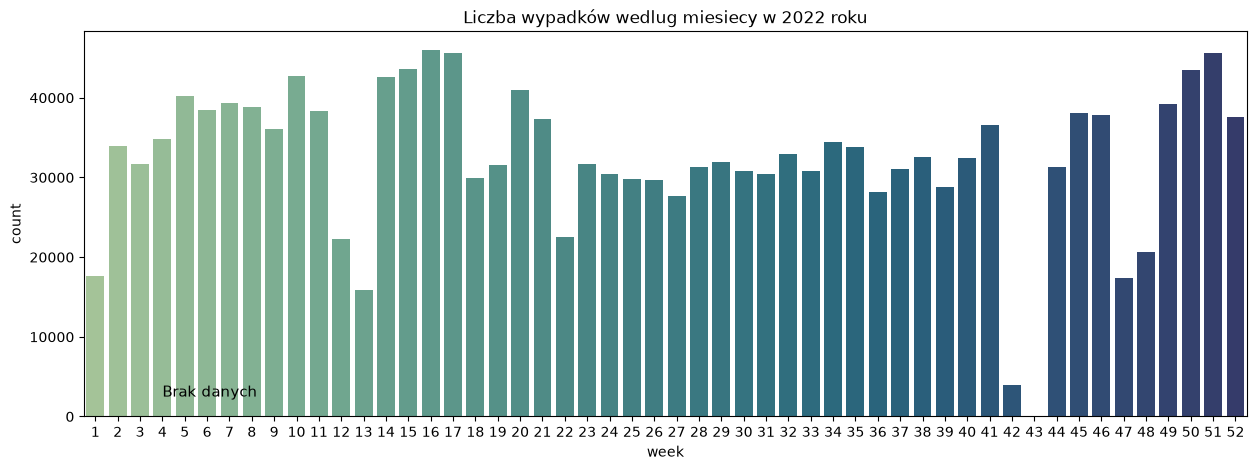

In [23]:
fig, ax = plt.subplots(figsize = (15,5))
c = sns.countplot(x=data_2022.Start_Time.dt.isocalendar().week, data=data_2022, orient = 'v', palette = "crest")
plt.annotate('Brak danych',xy=(3,2500), fontsize=11)
c.set_title("Liczba wypadków wedlug miesiecy w 2022 roku")
plt.show()

## Wszystkie tygodnie w latach 2017-2019

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\3486371934.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x=data_2017_2019.Start_Time.dt.isocalendar().week, data=data_2017_2019, orient = 'v', palette = "crest")


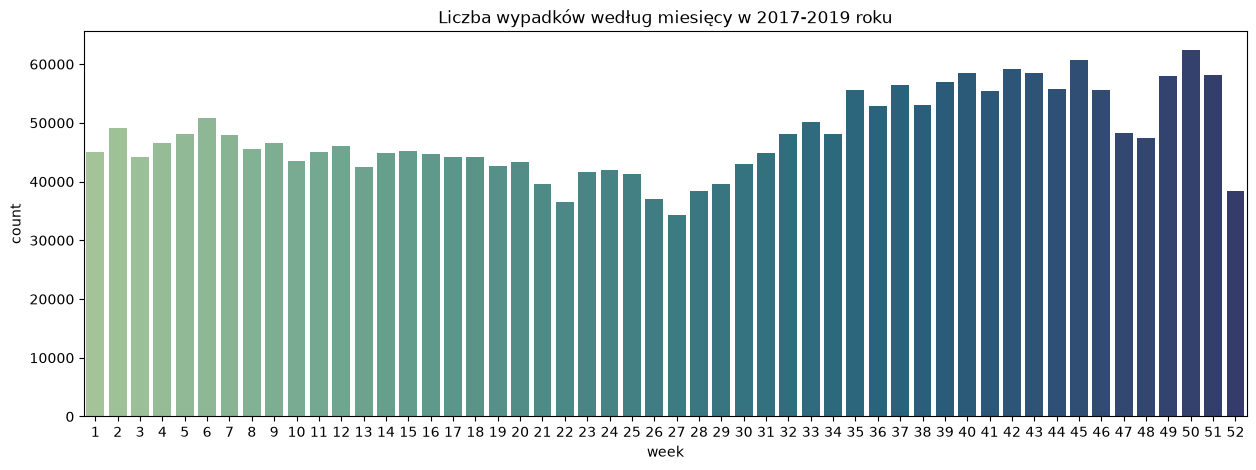

In [24]:
fig, ax = plt.subplots(figsize = (15,5))
c = sns.countplot(x=data_2017_2019.Start_Time.dt.isocalendar().week, data=data_2017_2019, orient = 'v', palette = "crest")
c.set_title("Liczba wypadków wedłuɡ miesięcy w 2017-2019 roku")
plt.show()

## Dni tygodnia

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\282558158.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Weekday", data=final_data, orient = 'v', palette = "crest_r")


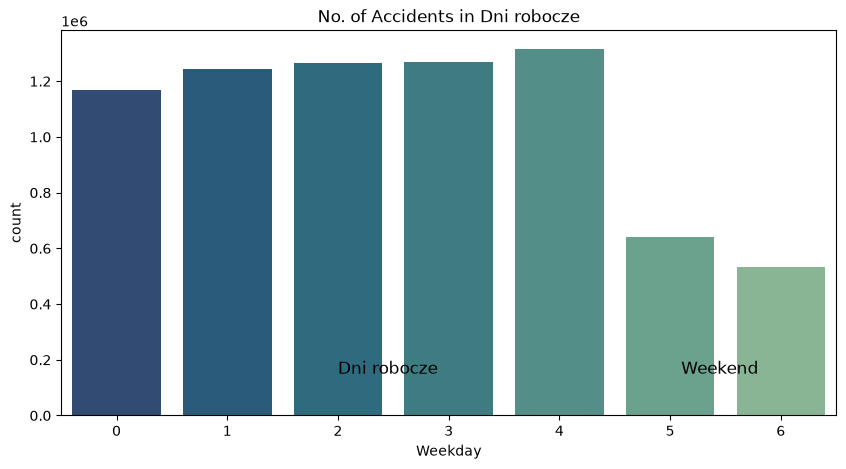

In [25]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Weekday", data=final_data, orient = 'v', palette = "crest_r")
plt.annotate('Dni robocze',xy=(2,150000), fontsize=12)
plt.annotate('Weekend',xy=(5.1,150000), fontsize=12)
c.set_title("No. of Accidents in Dni robocze")
plt.show()

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\413031497.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Hour", data=final_data, orient = 'v', palette = "icefire_r")


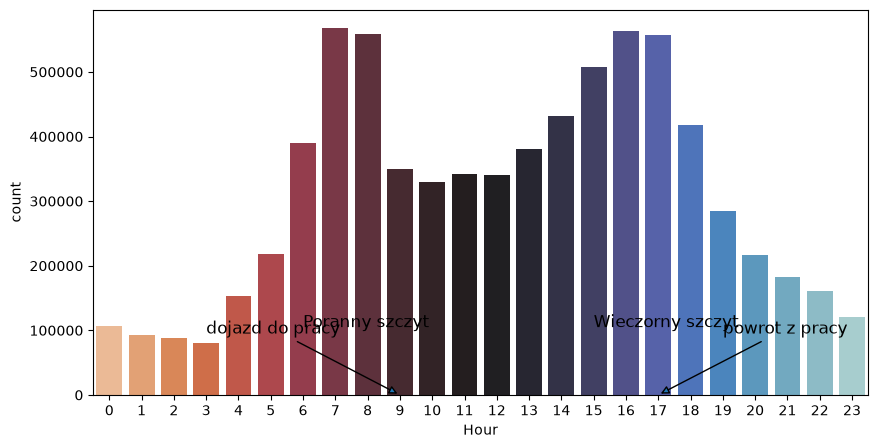

In [26]:
fig, ax = plt.subplots(figsize = (10,5))
sns.countplot(x="Hour", data=final_data, orient = 'v', palette = "icefire_r")
plt.annotate('Poranny szczyt',xy=(6,105000), fontsize=12)
plt.annotate('Wieczorny szczyt',xy=(15,105000), fontsize=12)
plt.annotate('dojazd do pracy',xy=(9,0),xytext=(3,95000),arrowprops={'arrowstyle':'-|>'}, fontsize=12)
plt.annotate('powrot z pracy',xy=(17,0),xytext=(19,95000),arrowprops={'arrowstyle':'-|>'}, fontsize=12)
plt.show()

## Analiza wypadkow wedlug stopnia ciezkosci

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\1023060346.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Severity", data=final_data, orient = 'v', palette = "crest_r")


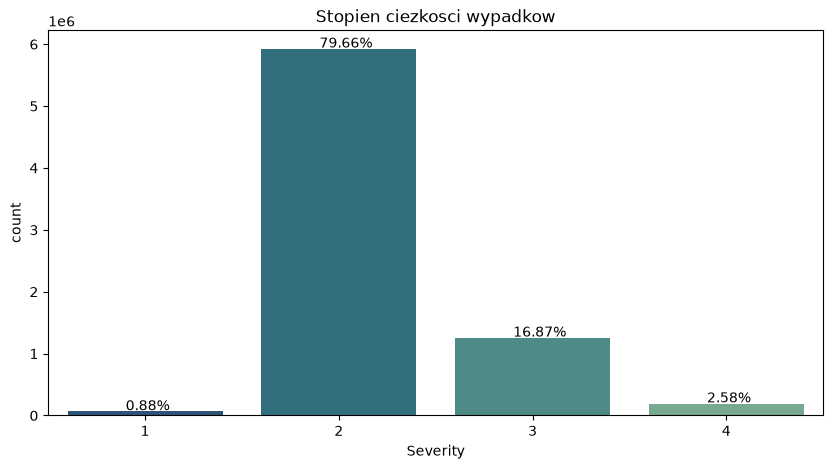

In [27]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Severity", data=final_data, orient = 'v', palette = "crest_r")
c.set_title("Stopien ciezkosci wypadkow")
for i in ax.patches:
    count = "{:.2%}".format(i.get_height()/len(final_data.Severity))
    x = i.get_x()+i.get_width()-0.50
    y = i.get_height()+20000
    ax.annotate(count, (x, y))
plt.show()

# Analiza danych pogodowych i lokalizacji wypadkow

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\755665034.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.barplot(x = 'State', y = 'Severity', data = df_state, orient = 'v', palette = "crest_r")


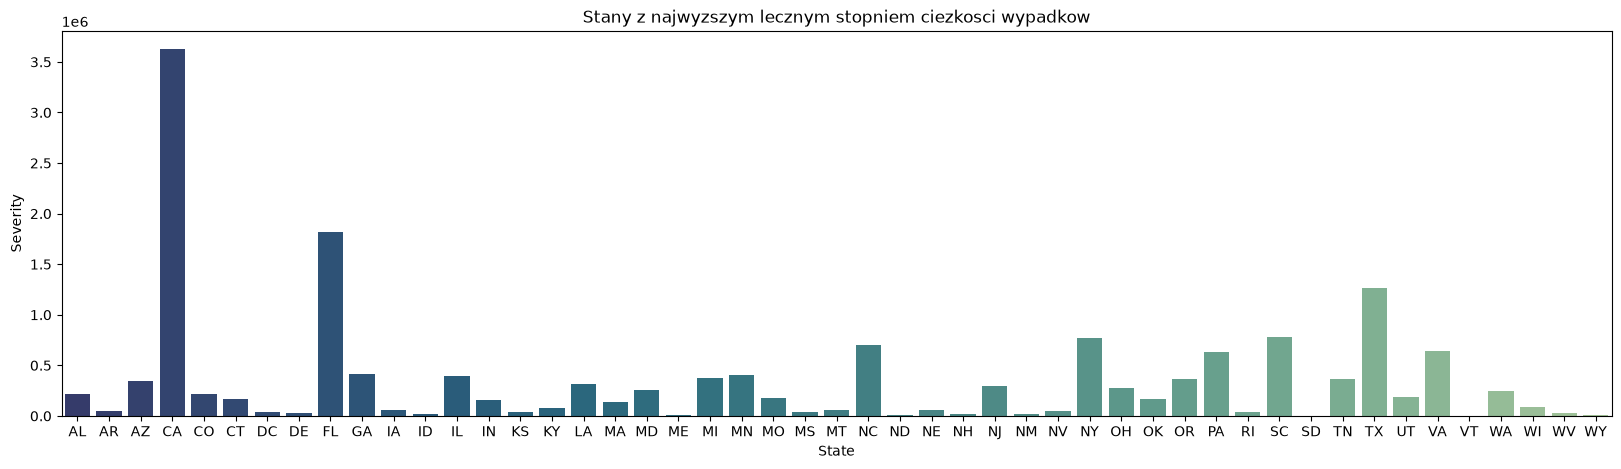

In [28]:
df_state = final_data.groupby('State')[['Severity']].sum()
df_state = df_state.reset_index().sort_values('Severity', ascending = False)[:50]
fig, ax = plt.subplots(figsize = (20,5))
c = sns.barplot(x = 'State', y = 'Severity', data = df_state, orient = 'v', palette = "crest_r")
c.set_title("Stany z najwyzszym lecznym stopniem ciezkosci wypadkow")
plt.show()

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\3449384973.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.barplot(x = 'City', y = 'Severity', data = df_city, orient = 'v', palette = "crest_r")
C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\3449384973.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  c.set_xticklabels(c.get_xticklabels(), rotation=90)


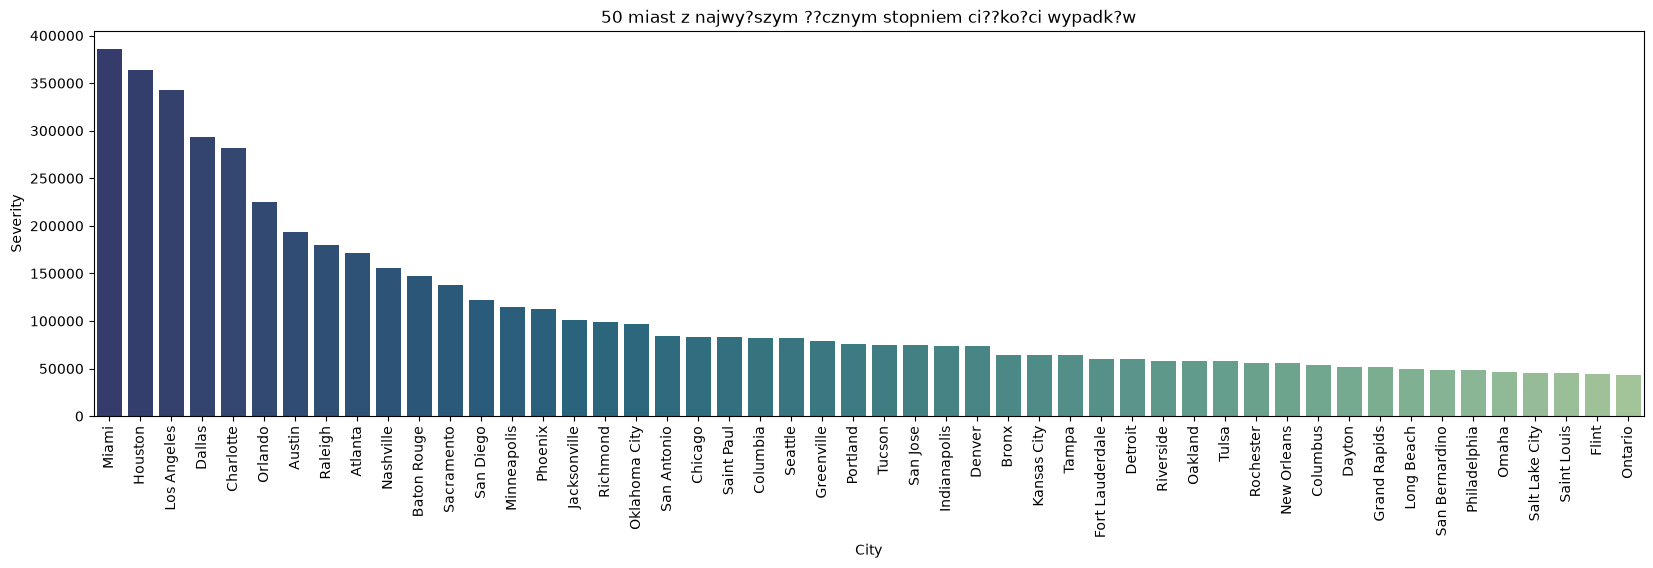

In [29]:
df_city = final_data.groupby('City')[['Severity']].sum()
df_city = df_city.reset_index().sort_values('Severity', ascending = False)[:50]
fig, ax = plt.subplots(figsize = (20,5))
c = sns.barplot(x = 'City', y = 'Severity', data = df_city, orient = 'v', palette = "crest_r")
c.set_title("50 miast z najwy?szym ??cznym stopniem ci??ko?ci wypadk?w")
c.set_xticklabels(c.get_xticklabels(), rotation=90)
plt.show()

# Wp?yw warunk?w pogodowych na wypadki

#### Powi?zane kolumny

In [30]:
weather = final_data.iloc[:, 17:26]
weather['Severity'] = final_data['Severity']
weather.head()

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Severity
0,36.900002,58.291424,91.0,29.680000,10.0,Calm,7.691033,0.020000,Light Rain,3
1,37.900002,58.291424,100.0,29.650000,10.0,Calm,7.691033,0.000000,Light Rain,2
2,36.000000,33.299999,100.0,29.670000,10.0,SW,3.500000,0.008018,Overcast,2
3,35.099998,31.000000,96.0,29.639999,9.0,SW,4.600000,0.008018,Mostly Cloudy,3
4,36.000000,33.299999,89.0,29.650000,6.0,SW,3.500000,0.008018,Mostly Cloudy,2


## Usuwanie warto?ci odstaj?cych

<Axes: >

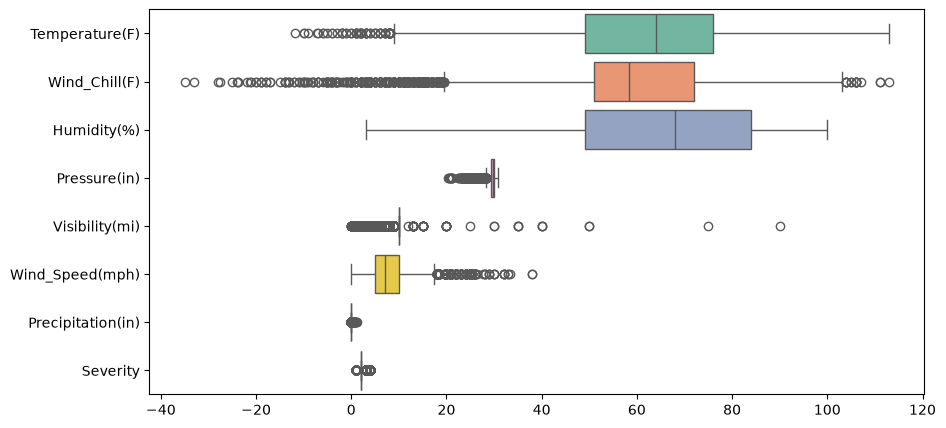

In [31]:
plt.figure(figsize=(10,5))
sns.boxplot(data=weather.sample(n=min(10_000, len(weather)), random_state=42).select_dtypes(include="number"), orient="h", palette="Set2")

In [32]:
def remove_outliers(df,name='feature'):
    #Store the 25th and 75th percentile 
    q25,q75=np.percentile(df[name],25),np.percentile(df[name],75)
    #Calculate the Interquartile range
    iqr_cut=1.5*(q75-q25)
    #Create variable of lower and upper cut
    lower,upper=q25-iqr_cut,q75+iqr_cut
    #Remove the outliers
    df=df[(df[name] >= lower) & (df[name] <= upper)]
    return df

In [33]:
weather = remove_outliers(weather,name='Temperature(F)')
weather = remove_outliers(weather,name='Wind_Chill(F)')
weather = remove_outliers(weather,name='Humidity(%)')
weather = remove_outliers(weather,name='Pressure(in)')
weather = remove_outliers(weather,name='Wind_Speed(mph)')

<Axes: >

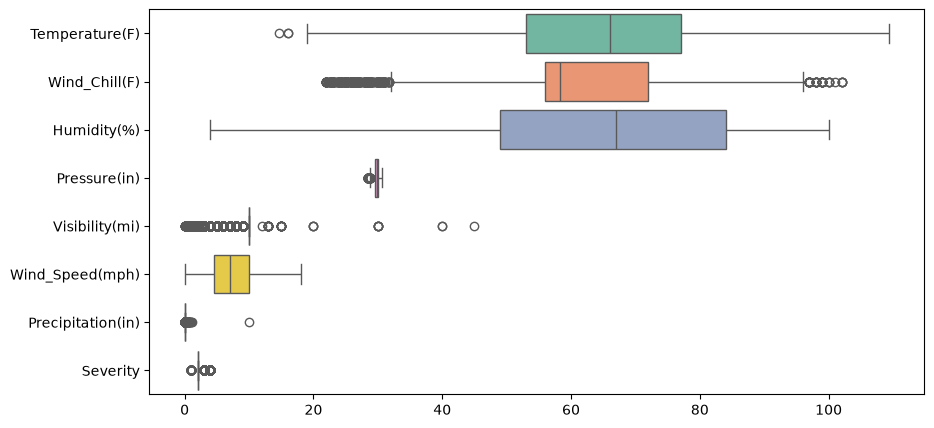

In [34]:
plt.figure(figsize=(10,5))
sns.boxplot(data=weather.sample(n=min(10_000, len(weather)), random_state=42).select_dtypes(include="number"), orient="h", palette="Set2")

## Temperatura (?F)

In [35]:
print("Unikalne warto?ci: ",weather["Temperature(F)"].nunique())
print("Brakuj?ce warto?ci: ",weather["Temperature(F)"].isna().sum())

Unikalne warto?ci:  615
Brakuj?ce warto?ci:  0


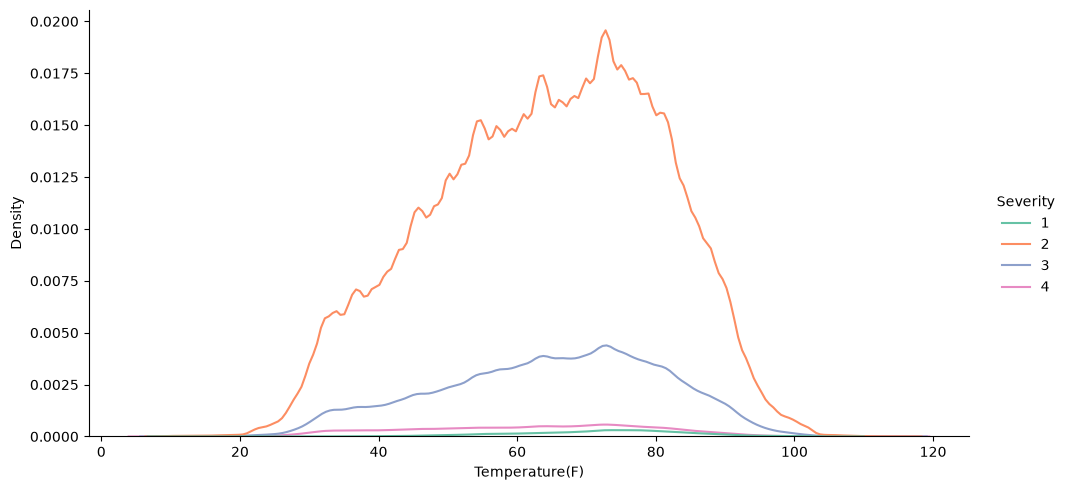

In [36]:
sns.displot(weather, x="Temperature(F)", hue="Severity",kind='kde', palette="Set2", height=5, aspect=2);

## Temperatura odczuwalna (?F)

In [37]:
print("Unikalne warto?ci: ",weather["Wind_Chill(F)"].nunique())
print("Brakuj?ce warto?ci: ",weather["Wind_Chill(F)"].isna().sum())
print("?rednia: ",weather["Wind_Chill(F)"].mean())

Unikalne warto?ci:  286
Brakuj?ce warto?ci:  0
?rednia:  61.143517


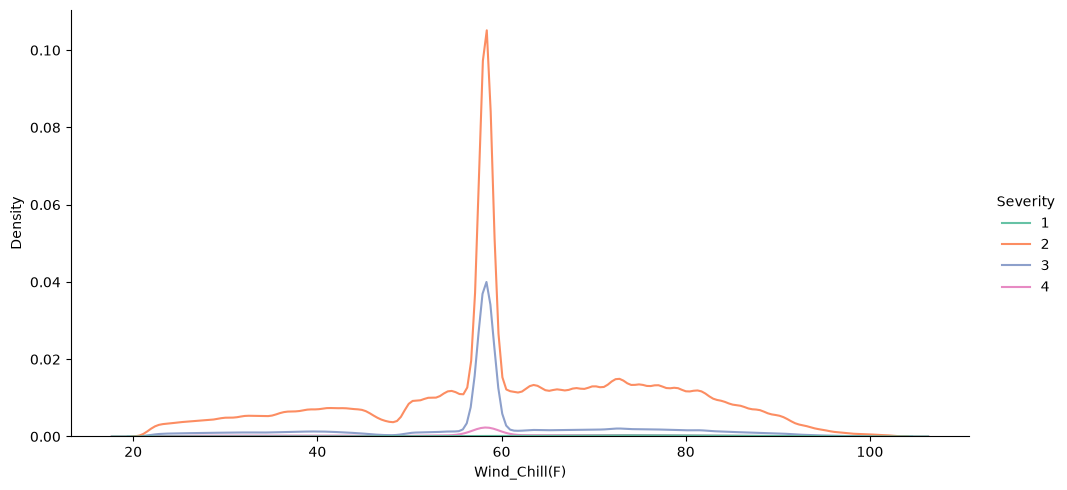

In [38]:
sns.displot(weather, x="Wind_Chill(F)", hue="Severity",kind='kde', palette="Set2", height=5, aspect=2);

## Wilgotno?? (%)

In [39]:
print("Unikalne warto?ci: ",weather["Humidity(%)"].nunique())
print("Brakuj?ce warto?ci: ",weather["Humidity(%)"].isna().sum())

Unikalne warto?ci:  100
Brakuj?ce warto?ci:  0


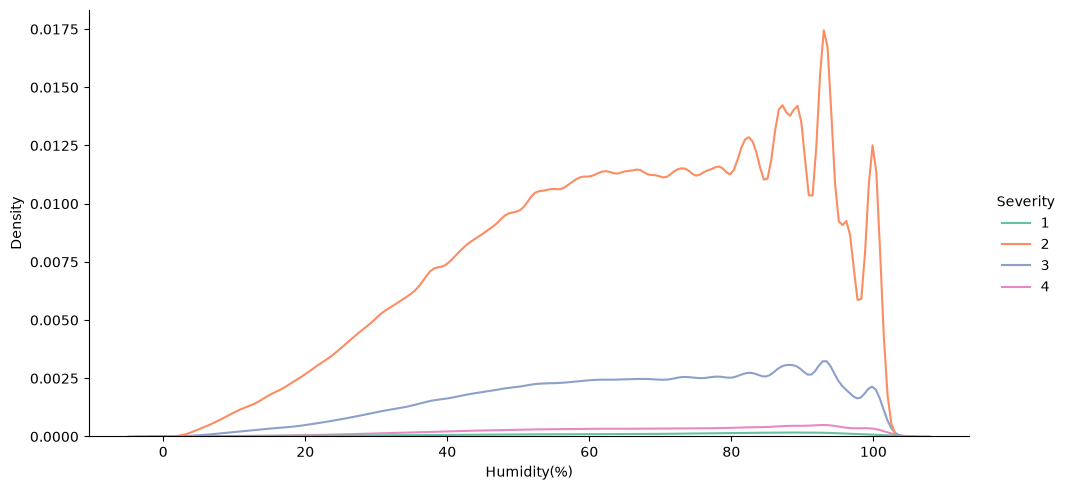

In [40]:
sns.displot(weather, x="Humidity(%)", hue="Severity",kind='kde', palette="Set2", height=5, aspect=2);

## Ci?nienie (cale s?upa rt?ci)

In [41]:
print("Brakuj?ce warto?ci: ",weather["Pressure(in)"].isna().sum())

Brakuj?ce warto?ci:  0


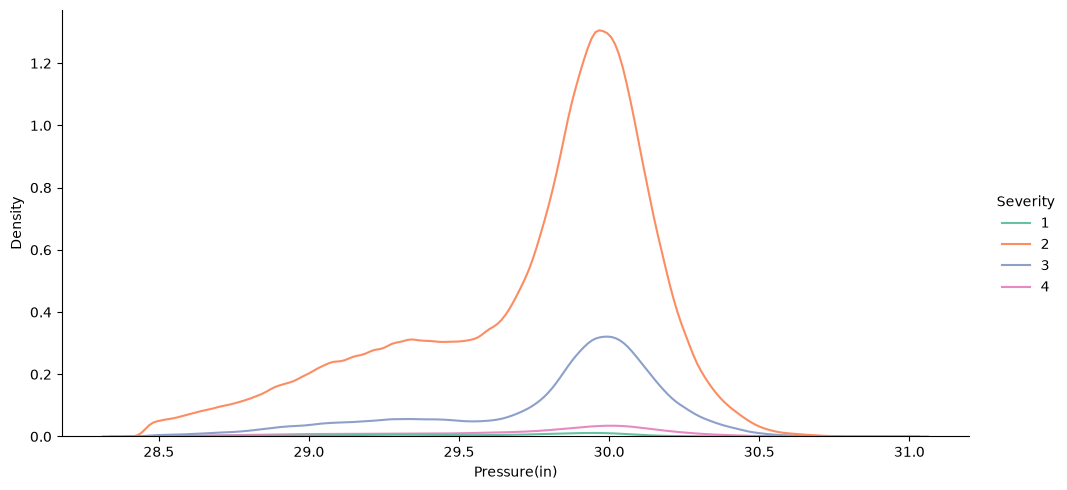

In [42]:
sns.displot(weather, x="Pressure(in)", hue="Severity",kind='kde', palette="Set2", height=5, aspect=2);

## Widoczno?? (mile)

In [43]:
print("Unikalne warto?ci: ",weather["Visibility(mi)"].nunique())
print("Brakuj?ce warto?ci: ",weather["Visibility(mi)"].isna().sum())

Unikalne warto?ci:  82
Brakuj?ce warto?ci:  0


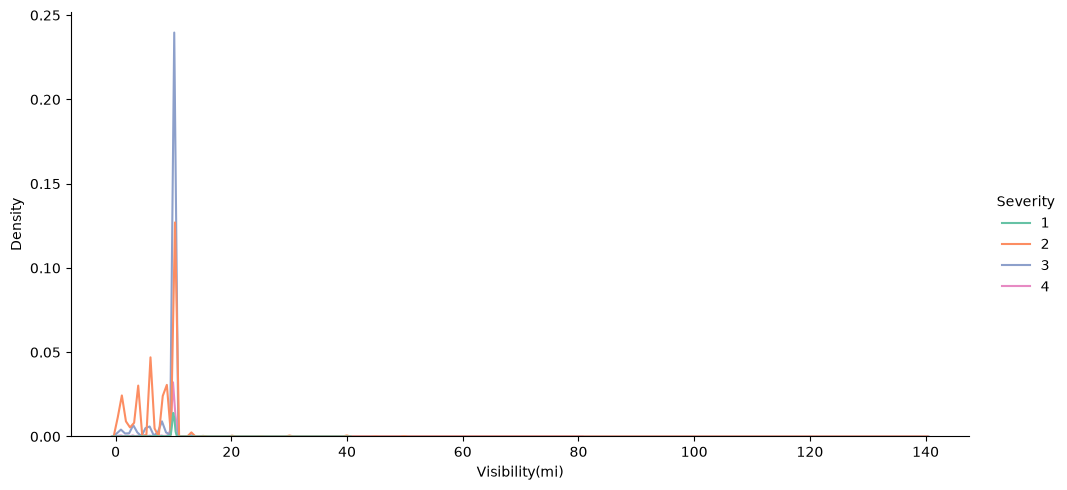

In [44]:
sns.displot(weather, x="Visibility(mi)", hue="Severity",kind='kde', palette="Set2", height=5, aspect=2);

## Kierunek wiatru

In [45]:
print("Unikalne kategorie: ",weather["Wind_Direction"].unique())
print("Unikalne warto?ci: ",weather["Wind_Direction"].nunique())

Unikalne kategorie:  ['Calm', 'SW', 'SSW', 'WSW', 'WNW', ..., 'Variable', 'S', 'VAR', 'CALM', 'N']
Length: 24
Categories (24, str): ['CALM', 'Calm', 'E', 'ENE', ..., 'W', 'WNW', 'WSW', 'West']
Unikalne warto?ci:  24


C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2869920776.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Wind_Direction",
C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2869920776.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Wind_Direction",


<Axes: xlabel='Wind_Direction', ylabel='count'>

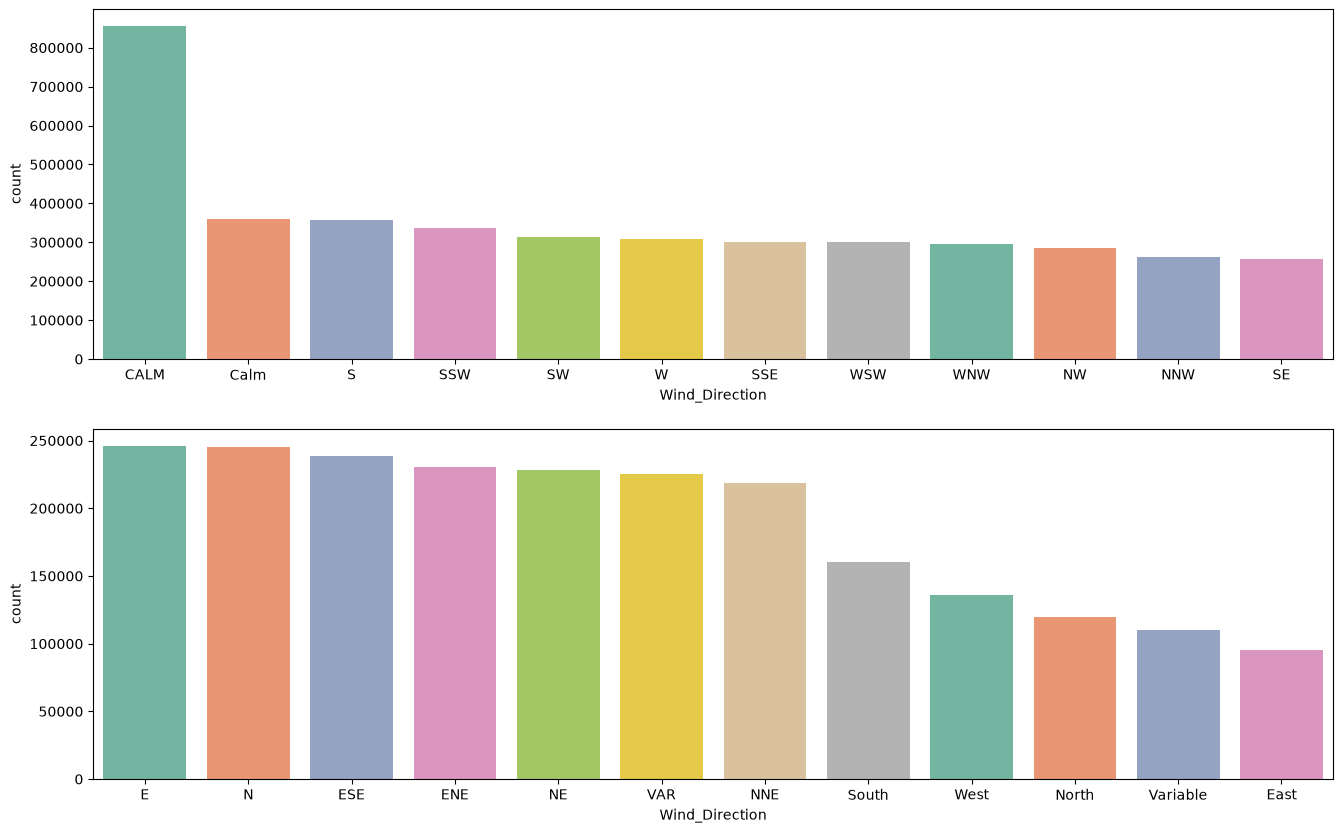

In [46]:
f,ax=plt.subplots(2,figsize=(16,10))
sns.countplot(x="Wind_Direction",
              data=weather,
              order=weather.Wind_Direction.value_counts().iloc[0:12].index,
              palette="Set2",
              ax=ax[0])
sns.countplot(x="Wind_Direction",
              data=weather,
              order=weather.Wind_Direction.value_counts().iloc[12:24].index,
              palette="Set2",
              ax=ax[1])

## Pr?dko?? wiatru (mile/h)

In [47]:
print("Unikalne warto?ci: ",weather["Wind_Speed(mph)"].nunique())

Unikalne warto?ci:  32


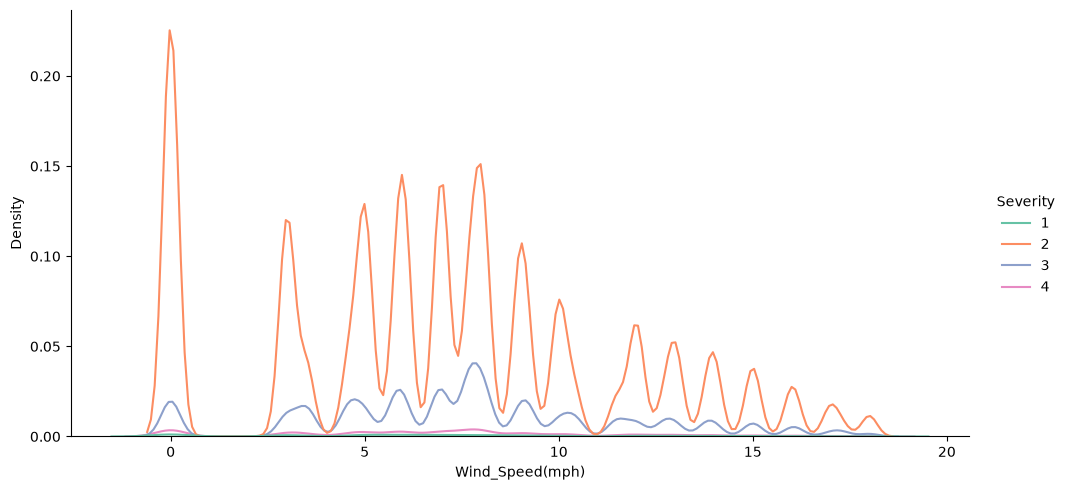

In [48]:
sns.displot(weather, x="Wind_Speed(mph)", hue="Severity",kind='kde', palette="Set2", height=5, aspect=2);

## Warunki pogodowe

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2546246270.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Weather_Condition",
C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2546246270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Weather_Condition",
C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2546246270.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Weather_Condition",
C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\2546246270.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprec

<Axes: xlabel='Weather_Condition', ylabel='count'>

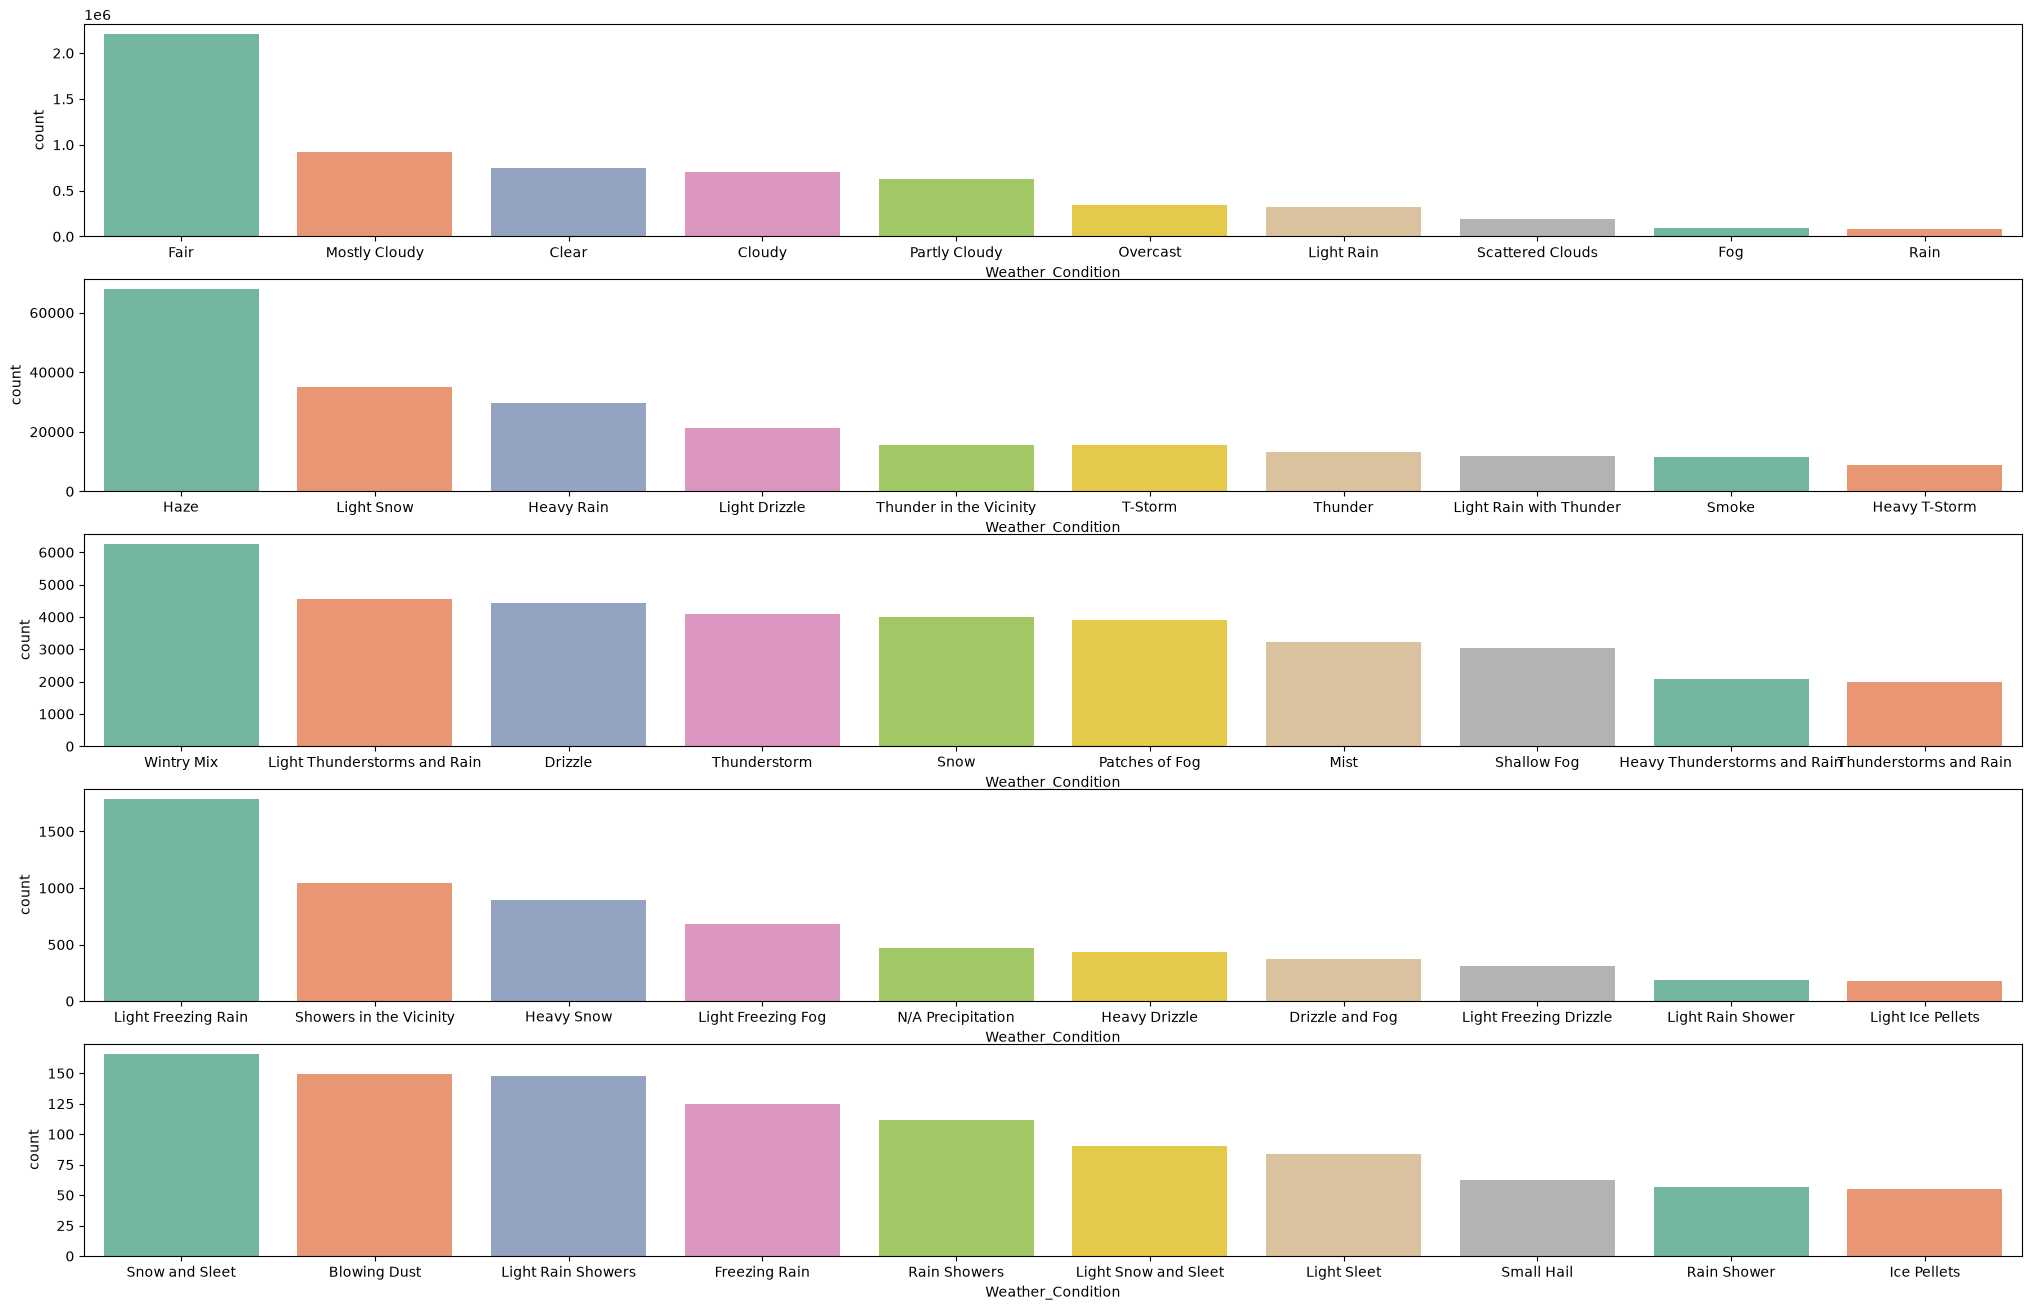

In [49]:
f,ax=plt.subplots(5,figsize=(25,16))
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[0:10].index,
              palette="Set2",
              ax=ax[0])
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[10:20].index,
              palette="Set2",
              ax=ax[1])
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[20:30].index,
              palette="Set2",
              ax=ax[2])
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[30:40].index,
              palette="Set2",
              ax=ax[3])
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[40:50].index,
              palette="Set2",
              ax=ax[4])

# Wp?yw lokalizacji na wypadki

#### Powi?zane kolumny

In [50]:
location = final_data.iloc[:, 26:39]
location.head()

,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False


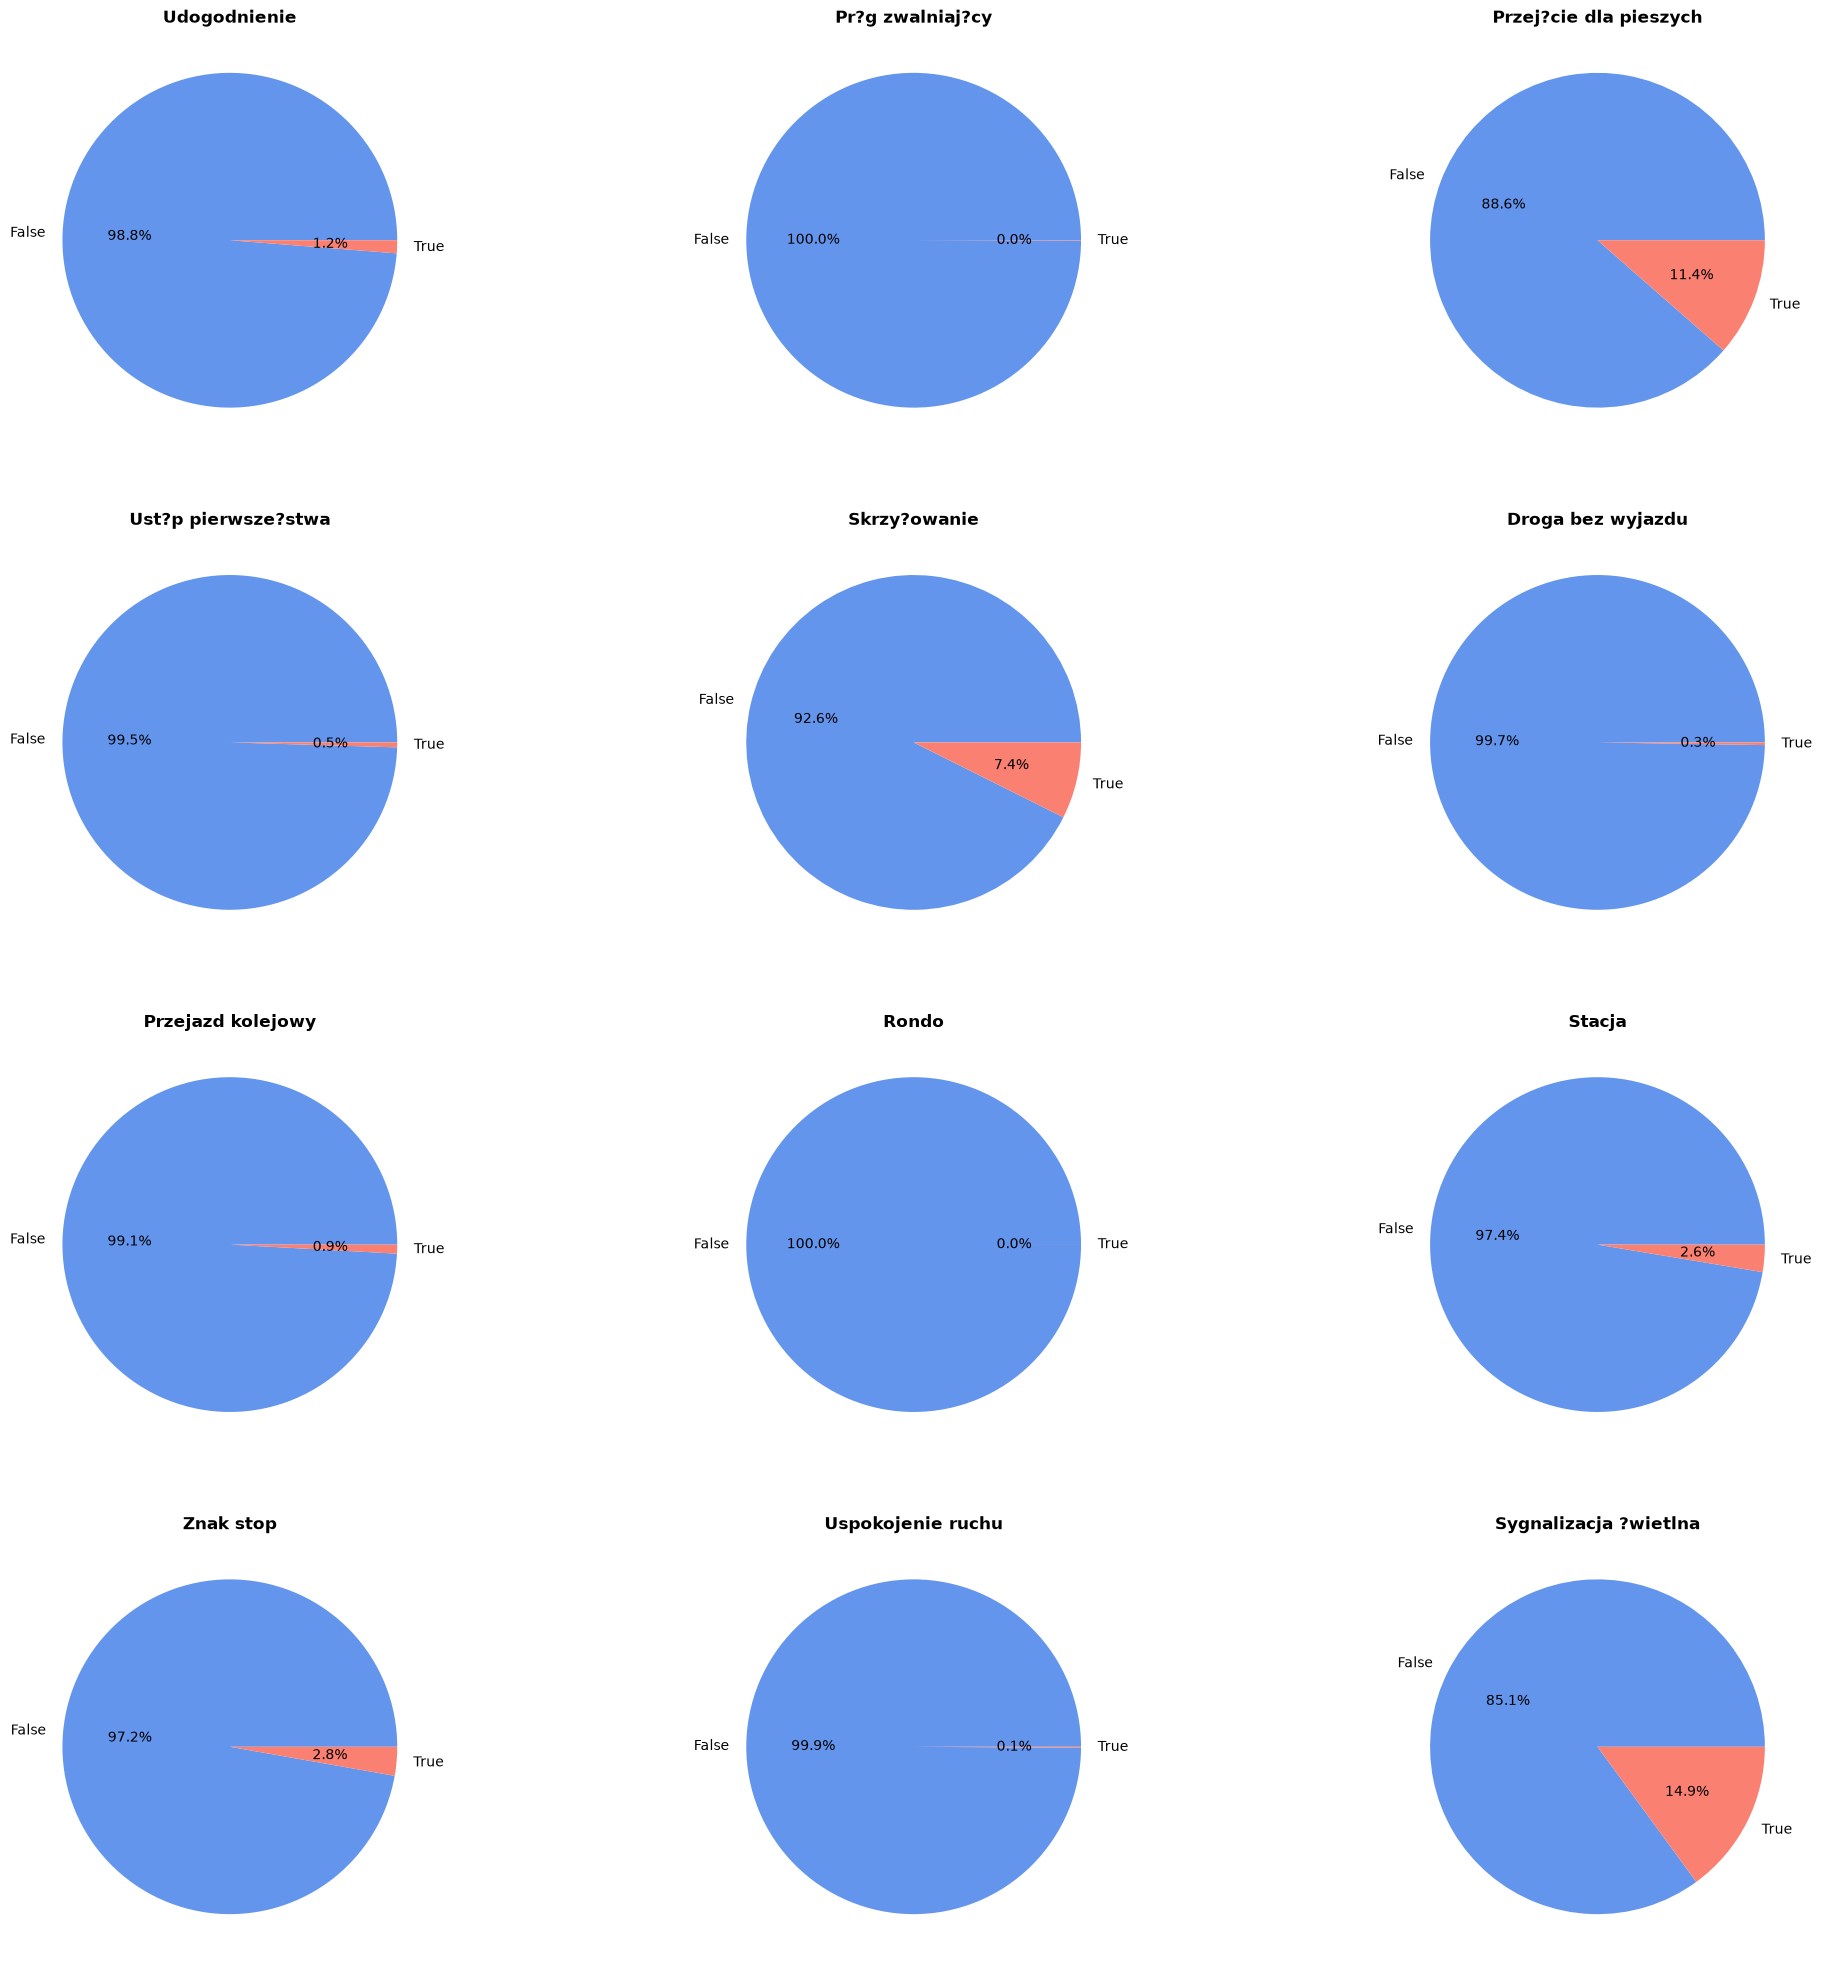

In [51]:
f,ax=plt.subplots(4,3,figsize=(25,25))
ax[0,0] = location['Amenity'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[0,0],colors=["cornflowerblue","salmon"])
ax[0,0].set_title("Udogodnienie",fontweight ="bold")
ax[0,1] = location['Bump'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[0,1],colors=["cornflowerblue","salmon"])
ax[0,1].set_title("Pr?g zwalniaj?cy",fontweight ="bold")
ax[0,2] = location['Crossing'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[0,2],colors=["cornflowerblue","salmon"])
ax[0,2].set_title("Przej?cie dla pieszych",fontweight ="bold")
ax[1,0] = location['Give_Way'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[1,0],colors=["cornflowerblue","salmon"])
ax[1,0].set_title("Ust?p pierwsze?stwa",fontweight ="bold")
ax[1,1] = location['Junction'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[1,1],colors=["cornflowerblue","salmon"])
ax[1,1].set_title("Skrzy?owanie",fontweight ="bold")
ax[1,2] = location['No_Exit'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[1,2],colors=["cornflowerblue","salmon"])
ax[1,2].set_title("Droga bez wyjazdu",fontweight ="bold")
ax[2,0] = location['Railway'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[2,0],colors=["cornflowerblue","salmon"])
ax[2,0].set_title("Przejazd kolejowy",fontweight ="bold")
ax[2,1] = location['Roundabout'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[2,1],colors=["cornflowerblue","salmon"])
ax[2,1].set_title("Rondo",fontweight ="bold")
ax[2,2] = location['Station'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[2,2],colors=["cornflowerblue","salmon"])
ax[2,2].set_title("Stacja",fontweight ="bold")
ax[3,0] = location['Stop'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[3,0],colors=["cornflowerblue","salmon"])
ax[3,0].set_title("Znak stop",fontweight ="bold")
ax[3,1] = location['Traffic_Calming'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[3,1],colors=["cornflowerblue","salmon"])
ax[3,1].set_title("Uspokojenie ruchu",fontweight ="bold")
ax[3,2] = location['Traffic_Signal'].value_counts().plot.pie(autopct='%1.1f%%',ax=ax[3,2],colors=["cornflowerblue","salmon"])
ax[3,2].set_title("Sygnalizacja ?wietlna",fontweight ="bold")
plt.show()

# Przygotowanie danych do modelowania stopnia ciezkosci wypadku

Ta sekcja wykonuje tylko preprocessing: nie trenuje ani nie ocenia modelu. Oryginalna ramka `df` i jej kolumny pozostaja bez zmian. Wynikami sa przygotowane cechy, wagi klas i indeksy foldow. Przy pozniejszej ocenie modelu preprocessing nalezy dopasowywac osobno w kazdym foldzie, aby uniknac przecieku danych.

In [52]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

TARGET_COLUMN = "Severity"
CV_FOLDS = 5
CV_SAMPLE_LIMIT = 100_000
RANDOM_STATE = 42

if TARGET_COLUMN not in df.columns:
    raise KeyError(f"Missing target column: {TARGET_COLUMN}")
if "Start_Time" not in df.columns:
    raise KeyError("Missing Start_Time required for time feature engineering")

numeric_candidates = [
    "Start_Lat", "Start_Lng", "Distance(mi)", "Temperature(F)",
    "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
    "Wind_Speed(mph)", "Precipitation(in)",
]
categorical_candidates = [
    "Source", "State", "Weather_Condition", "Wind_Direction", "Timezone",
    "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight",
    "Astronomical_Twilight",
]
binary_candidates = [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
    "Traffic_Signal", "Turning_Loop",
]

numeric_features = [column for column in numeric_candidates if column in df.columns]
categorical_features = [column for column in categorical_candidates if column in df.columns]
categorical_features += [column for column in binary_candidates if column in df.columns]
model_feature_columns = numeric_features + categorical_features
if not model_feature_columns:
    raise ValueError("No model input features were found")

y_all = df.loc[df[TARGET_COLUMN].notna(), TARGET_COLUMN]
class_counts = y_all.value_counts()
if len(class_counts) < 2:
    raise ValueError("At least two Severity classes are required")
if class_counts.min() < CV_FOLDS:
    raise ValueError(
        f"The rarest class has {class_counts.min()} records; "
        f"not enough for {CV_FOLDS}-fold cross-validation"
    )

if len(y_all) > CV_SAMPLE_LIMIT:
    model_indices, _ = train_test_split(
        y_all.index.to_numpy(),
        train_size=CV_SAMPLE_LIMIT,
        random_state=RANDOM_STATE,
        stratify=y_all.to_numpy(),
    )
    model_indices = pd.Index(model_indices)
else:
    model_indices = y_all.index

# Work on a copy so the source dataframe and its columns remain unchanged.
X_model = df.loc[model_indices, model_feature_columns].copy()
y_model = y_all.loc[model_indices].copy()

start_time = pd.to_datetime(
    df.loc[model_indices, "Start_Time"], errors="coerce", format="mixed"
)
engineered_features = {
    "Hour_sin": np.sin(2 * np.pi * start_time.dt.hour / 24),
    "Hour_cos": np.cos(2 * np.pi * start_time.dt.hour / 24),
    "Weekday_sin": np.sin(2 * np.pi * start_time.dt.weekday / 7),
    "Weekday_cos": np.cos(2 * np.pi * start_time.dt.weekday / 7),
    "Month_sin": np.sin(2 * np.pi * (start_time.dt.month - 1) / 12),
    "Month_cos": np.cos(2 * np.pi * (start_time.dt.month - 1) / 12),
}
if set(engineered_features).intersection(df.columns):
    raise ValueError("Engineered feature names conflict with existing df columns")
for feature_name, values in engineered_features.items():
    X_model[feature_name] = values
numeric_features += list(engineered_features)

for column in numeric_features:
    X_model[column] = pd.to_numeric(X_model[column], errors="coerce")
for column in categorical_features:
    X_model[column] = X_model[column].astype("object").where(
        X_model[column].notna(), np.nan
    )

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# Prepare class weights and CV folds; no classifier is trained here.
sample_weights = pd.Series(
    compute_sample_weight(class_weight="balanced", y=y_model),
    index=y_model.index,
    name="sample_weight",
)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_model, y_model))

# Fit only the preprocessing transformations; no estimator is trained.
X_preprocessed = preprocessor.fit_transform(X_model)
prepared_feature_names = preprocessor.get_feature_names_out()
print("Class counts in source data:\n", class_counts)
print(f"Records in preprocessing sample: {len(y_model):,}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical/binary features: {len(categorical_features)}")
print(f"Prepared feature matrix shape: {X_preprocessed.shape}")
print(f"Prepared feature names: {len(prepared_feature_names)}")
print(f"Stratified CV folds: {len(cv_splits)}")
print("Sample weights:", sample_weights.describe())

C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\1263691524.py:74: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  "Weekday_sin": np.sin(2 * np.pi * start_time.dt.weekday / 7),
C:\Users\kubaz\AppData\Local\Temp\ipykernel_9492\1263691524.py:75: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  "Weekday_cos": np.cos(2 * np.pi * start_time.dt.weekday / 7),


Class counts in source data:
 Severity
2    6156981
3    1299337
4     204710
1      67366
Name: count, dtype: int64
Records in preprocessing sample: 100,000
Numeric features: 16
Categorical/binary features: 22
Prepared feature matrix shape: (100000, 208)
Prepared feature names: 208
Stratified CV folds: 5
Sample weights: count    100000.000000
mean          1.000000
std           2.996183
min           0.313806
25%           0.313806
50%           0.313806
75%           0.313806
max          28.669725
Name: sample_weight, dtype: float64
